# mutascape demo

Synthetic combinatorial fitness landscapes on **CreiLOV**, a fluorescent LOV-domain protein with 118 mutable positions and real single-site DMS data.

## Load data

Contact map extracted from PDB 4I6G (see `data/creilov/prepare_creilov.py`).

Alternatively, predict structure from sequence with no PDB needed:
```python
contacts = ContactMap.from_sequence(wt_seq, threshold=8.0)  # uses ESMFold
```

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from Bio import SeqIO

from mutascape import ContactMap, Landscape, Mutant, RandomEpistasis, SignConsistentEpistasis

In [2]:
# Load pre-extracted CreiLOV contact map (from PDB 4I6G, chain A)
# See data/creilov/prepare_creilov.py for processing steps

# data = np.load("../data/creilov/creilov_distances.npz")
# contacts = ContactMap.from_distance_matrix(
#     data["distances"], data["positions"].tolist(), threshold=8.0
# )
wt_seq = str(next(SeqIO.parse("../data/creilov/creilov_wt.fasta", "fasta")).seq)

# Alternatively, predict structure from contacts using ESM fold
contacts = ContactMap.from_sequence(wt_seq, threshold=8.0)

print(f"CreiLOV: {len(wt_seq)} residues, {contacts.n_contacts} structural contacts")
print(f"DMS data: {len(pd.read_csv('../data/creilov/creilov.csv'))} single-site variants")

CreiLOV: 119 residues, 531 structural contacts
DMS data: 2121 single-site variants


## Build landscape

In [3]:
landscape = Landscape.from_dms(
    dms_path="../data/creilov/creilov.csv",
    contact_map=contacts,
    epistasis=RandomEpistasis(sigma=0.3, seed=42),
    alpha=1.0,
    seed=42,
    wt_sequence=wt_seq,
)
landscape

Landscape(positions=[2(A), 3(G), 4(L), 5(R), 6(H), 7(T), 8(F), 9(V), 10(V), 11(A), 12(D), 13(A), 14(T), 15(L), 16(P), 17(D), 18(C), 19(P), 20(L), 21(V), 22(Y), 23(A), 24(S), 25(E), 26(G), 27(F), 28(Y), 29(A), 30(M), 31(T), 32(G), 33(Y), 34(G), 35(P), 36(D), 37(E), 38(V), 39(L), 40(G), 41(H), 42(N), 43(A), 44(R), 45(F), 46(L), 47(Q), 48(G), 49(E), 50(G), 51(T), 52(D), 53(P), 54(K), 55(E), 56(V), 57(Q), 58(K), 59(I), 60(R), 61(D), 62(A), 63(I), 64(K), 65(K), 66(G), 67(E), 68(A), 69(C), 70(S), 71(V), 72(R), 73(L), 74(L), 75(N), 76(Y), 77(R), 78(K), 79(D), 80(G), 81(T), 82(P), 83(F), 84(W), 85(N), 86(L), 87(L), 88(T), 89(V), 90(T), 91(P), 92(I), 93(K), 94(T), 95(P), 96(D), 97(G), 98(R), 99(V), 100(S), 101(K), 102(F), 103(V), 104(G), 105(V), 106(Q), 107(V), 108(D), 109(V), 110(T), 111(S), 112(K), 113(T), 114(E), 115(G), 116(K), 117(A), 118(L), 119(A)], alpha=1.0, contacts=528, seq_len=119)

## Querying the oracle

In [20]:
# Single mutant: just the DMS fitness effect
landscape["A60A"]

0.181577303

In [5]:
# Combine mutations with + operator
m = Mutant("A29H") + Mutant("R60D") + Mutant("F84W")
print(f"{m}")
print(f"  additive prediction: {landscape.additive_fitness(m):+.4f}")
print(f"  actual fitness:      {landscape[m]:+.4f}")

A29H+R60D+F84W
  additive prediction: +0.4949
  actual fitness:      +0.4949


In [6]:
# Full mutant sequence
landscape.mutant_sequence(m)

'MAGLRHTFVVADATLPDCPLVYASEGFYHMTGYGPDEVLGHNARFLQGEGTDPKEVQKIDDAIKKGEACSVRLLNYRKDGTPFWNLLTVTPIKTPDGRVSKFVGVQVDVTSKTEGKALA'

## Streaming with `generate()`

In [7]:
# Sample 3-mutants on demand
for v in landscape.generate(n_mutations=3, n=5, seed=99):
    print(f"{v.mutations!s:30s}  fitness={v.fitness:+.4f}")

D61P+P91Q+T113V                 fitness=-0.4570
L39P+L73P+T113E                 fitness=-0.4157
T14F+N42P+V56N                  fitness=+0.0656
V38F+N42L+V71G                  fitness=-1.3417
F83G+P91R+S111K                 fitness=-1.2602


In [8]:
# Infinite generator: search for a high-fitness variant
best = None
for i, v in enumerate(landscape.generate(n_mutations=4)):
    if best is None or v.fitness > best.fitness:
        best = v
    if best.fitness > 18.0 or i > 5000:
        break
print(f"Best after {i+1} samples: {best.mutations}  fitness={best.fitness:+.4f}")

Best after 5002 samples: H6K+E25Q+R72D+T113W  fitness=+1.8914


## Bulk sampling

In [9]:
df = landscape.to_dataframe(n_variants=5000, n_mutations=(1, 5), seed=42)
print(f"{len(df)} unique variants across depths {df['n_mutations'].min()}-{df['n_mutations'].max()}")
df.head(10)

5000 unique variants across depths 1-5


,sequence,variant,fitness,n_mutations
0,MAGLRHTFVVADATLPDCPLVYASEGFYAMTGYGPDEVLGHNARFL...,K93Q,0.068434,1
1,MAGLRHTFVVAFATLPDCPLVYASEGFYAMTGYGPDEVLGHNARFL...,D12F+D52K+F102V,-0.656066,3
2,MAGLRHTFVVADATLPDCPLVYASEGFYAMTGYGPDEVLGHNARFL...,A62Y+N85P+V89P+K93T,-0.618322,4
3,MAGLRHTFVVADATLPDCPLVYASEGFYAMTGYGPDEVLGHNARFL...,G48R+G66Y+Y76Q+R98H,0.396643,4
4,MAGLRHTFVVADATLPDCPLYYASEGFYAMTGIGPDEVLGHNARFL...,V21Y+Y33I+N75L+P91F+D96L,-1.776369,5
5,MAGLRHTFVVADATLPDCPLVYASEGFYAMTGYGPDEVLGHNAHFL...,R44H,0.064929,1
6,MAGLRHWFVVADATLPDCPAVYASEGFYAMTGYGPDEVLGHNARFL...,T7W+L20A+K65N,-0.256934,3
7,MAGLRHTFVVHDATLPDCPLVYASEGFYAMTGYGPDEVKGHNARRL...,A11H+L39K+F45R+G48Q+V107D,-0.787967,5
8,MAGLRHTFVVADATLPDCPLVYASEGFYAMTGYGPDEVLGHNARFL...,P53A+D79N+K112F,0.332737,3
9,MAGLRHTFVVADATLPDCPLVYASEGFYAMTGYGPDEVLGHNARFL...,P91K+S100E,-0.376854,2


## Landscape characterisation + plots

In [10]:
landscape.stats(n_samples=2000, n_mutations=3)

{'mean_fitness': -0.12997417252158353,
 'std_fitness': 0.5888052643914286,
 'additive_correlation': 0.9363224304785841,
 'mean_epistatic_deviation': 0.07329190262911098,
 'fraction_sign_epistasis': 0.111}

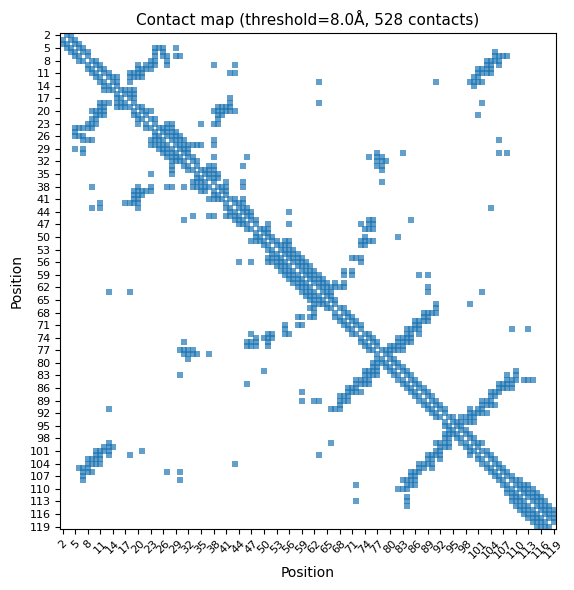

In [11]:
landscape.plot_contacts()

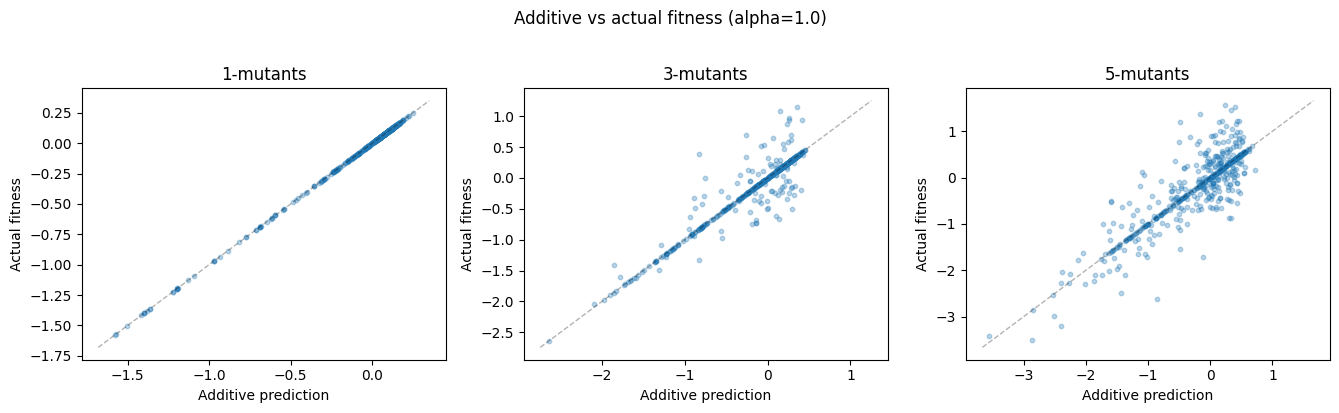

In [12]:
landscape.plot_epistasis(depths=[1, 3, 5]);

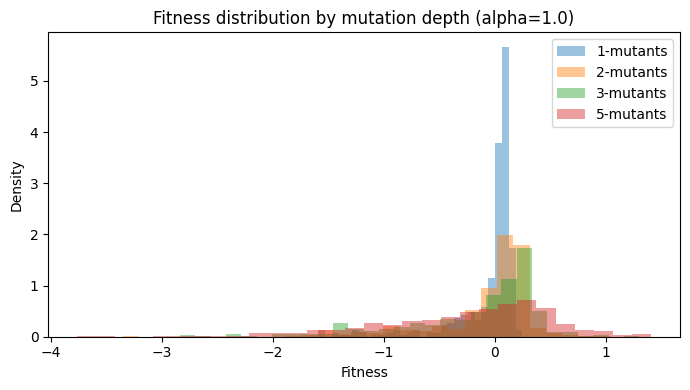

In [13]:
landscape.plot_fitness(depths=[1, 2, 3, 5]);

## Alpha sweep

,mean_fitness,std_fitness,additive_correlation,mean_epistatic_deviation,fraction_sign_epistasis
0.00,-0.116632,0.534120,1.000000,8.627647e-18,0.0000
0.25,-0.116595,0.535546,0.995102,1.953139e-02,0.0685
0.50,-0.116558,0.542166,0.980746,3.906277e-02,0.0995
1.00,-0.116485,0.570118,0.928464,7.812554e-02,0.1190
2.00,-0.116338,0.674175,0.778062,1.562511e-01,0.1315
5.00,-0.115898,1.175285,0.434103,3.906277e-01,0.1450


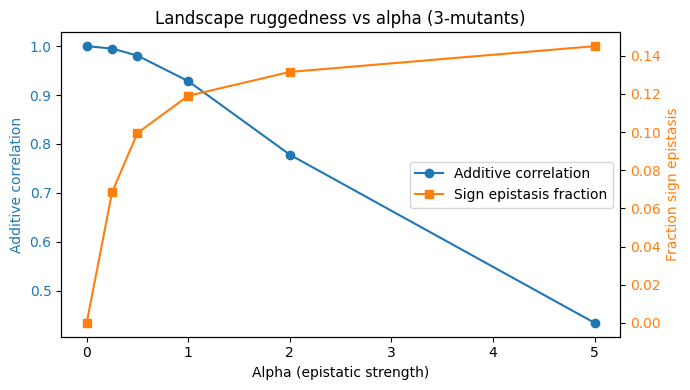

In [14]:
fig, sweep_data = landscape.plot_alpha_sweep()
pd.DataFrame(sweep_data).T

## Comparing epistasis models

In [15]:
for name, model in [
    ("Random", RandomEpistasis(sigma=0.3, seed=42)),
    ("SignConsistent", SignConsistentEpistasis(sigma=0.3, seed=42))
    ]:
    ls = Landscape.from_dms("../data/creilov/creilov.csv", contacts, model, alpha=1.0, seed=42, wt_sequence=wt_seq)
    s = ls.stats(n_samples=2000, n_mutations=3)
    print(f"{name:16s}  corr={s['additive_correlation']:.3f}  sign_epi={s['fraction_sign_epistasis']:.3f}")

Random            corr=0.928  sign_epi=0.119
SignConsistent    corr=0.974  sign_epi=0.092
